# 276. Does structure support P66 mimicking CD47? Whole fold, Foldseek and the loop against the binding face

## The claim, quoted

From [Tal et al. 2024, bioRxiv](https://doi.org/10.1101/2024.04.29.591704), "P66 is a
bacterial mimic of CD47 that binds the anti-phagocytic receptor SIRPα and facilitates
macrophage evasion by *Borrelia burgdorferi*" (PubMed 38746193). It is quoted in
[notebook 016](./016-ced9-bcl2-and-p66-cd47.ipynb), markdown cell 34:

> We have previously demonstrated that two aspartic acid residues, D184 and D186, on a
> predicted extracellular loop of P66 (181–187) are required for integrin binding. *B.
> burgdorferi* expressing the mutant D184A and D186A, p66D184A,D186A, or loss of the loop,
> p66Δ181−187, demonstrated loss of CV1-G4 binding (Figure 2A). Consistent to previous
> structure predictions, these sites map to an unstructured extracellular loop on a
> structure of P66 generated by Alphafold2 (Figure 2B and Extended Data 2A). We postulate
> this region is also required for SIRPɑ binding.

So the three parts of the claim are:

* **which P66 loop** — the predicted extracellular loop at mature residues 181-187,
  with the two aspartates D184 and D186;
* **which partner** — SIRPα, the receptor that CD47 binds;
* **which CD47 face** — the paper does not name CD47 residues. It says P66 is a mimic of
  CD47 and binds the same receptor, so the face this notebook tests against is the one
  CD47 actually uses: the CD47 residues that touch SIRPα in a crystal structure of the two
  together.

The same paper names the two accessions it worked with: CD47_HUMAN (Q08722) and
H7C7N8 (P66)_BORBU. Both were re-resolved live here from gene and taxon, and both came
back as the entries the paper names.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, str(Path.cwd()))

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(220)

DATA = Path("/Users/olga/data/nb276-p66-cd47-structure")
FIG = Path("../figures")
if not DATA.exists():
    raise SystemExit(
        "Run scripts/nb276_p66_cd47_structure.py and scripts/nb276_figures.py first."
    )


def show(stem, aspect=0.62):
    """Display a figure this notebook's figure script already saved."""
    fig, ax = plt.subplots(figsize=(9, 9 * aspect), layout="constrained")
    ax.imshow(plt.imread(FIG / f"{stem}.png"))
    ax.axis("off")

## The question and the rule for answering it

Does the structure support mimicry? The rule was set before any number was computed, in
the task that asked for this notebook:

> The claimed pair has to beat both backgrounds, or the result is that it does not.

Spelled out:

| comparison | what would support mimicry | what would not |
|---|---|---|
| whole fold | P66's TM-score against CD47's IgV domain sits inside or above the range of 20 unrelated immunoglobulin domains against the same CD47 domain | it sits below all of them |
| the loop against the face | the claimed loop's backbone RMSD on the binding face is lower than 10 other P66 loops of the same length | it is not lower |

Higher TM-score means more alike. Lower RMSD means a better fit. Both backgrounds have to
be beaten, because both quantities are easy to reach by accident: any immunoglobulin domain
resembles CD47, and any 7-residue stretch can be laid on any other with a small RMSD.

**What decision this changes.** If structure supported the mimicry, P66 and CD47 would be a
real pair of proteins that share a function through shape without sharing sequence, and
that is exactly the case kmerseek is built to find. The project could then use it as a
test case the way Bcl-2 and Ced-9 are used. If structure does not support it, the pair
stops being a candidate for that role, and the kmerseek negative in
[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96) stops needing an
explanation.

### Two numbering systems

The paper numbers the mature chain; UniProt and the AlphaFold model number the precursor.
Mixing them is the easiest way to get a wrong answer, so both appear in every table.

| protein | signal peptide | mature 1 is | the loop or face, mature | the same, UniProt |
|---|---|---|---|---|
| P66, H7C7N8 | 1-21 | UniProt 22 | 181-187, D184 and D186 | 202-208, D205 and D207 |
| CD47, Q08722 | 1-18 | UniProt 19 | numbering of PDB 2JJS chain C | add 18 |

Reading the mapping off the entry rather than assuming it matters: at UniProt 181-187 the
P66 sequence is `YKLPKLD`, which has no aspartate where the paper says, while at 202-208 it
is `QENDKDT`, with D at 205 and D at 207. The script refuses to continue if that check
fails.

The claim drawn out, before any measurement:

Accessions resolved live from UniProt by gene and taxon:
shape: (2, 7)
┌───────────┬──────────────┬─────────────────────────────────┬────────┬────────────────────┬─────────────────────────────────┬───────────┐
│ accession ┆ entry_name   ┆ protein_name                    ┆ length ┆ signal_peptide_end ┆ reviewed                        ┆ role      │
│ ---       ┆ ---          ┆ ---                             ┆ ---    ┆ ---                ┆ ---                             ┆ ---       │
│ str       ┆ str          ┆ str                             ┆ i64    ┆ i64                ┆ str                             ┆ str       │
╞═══════════╪══════════════╪═════════════════════════════════╪════════╪════════════════════╪═════════════════════════════════╪═══════════╡
│ H7C7N8    ┆ H7C7N8_BORBU ┆ Integral outer membrane protei… ┆ 618    ┆ 21                 ┆ UniProtKB unreviewed (TrEMBL)   ┆ P66 query │
│ Q08722    ┆ CD47_HUMAN   ┆ Leukocyte surface antigen CD47  ┆ 323    ┆ 18                 ┆ Un

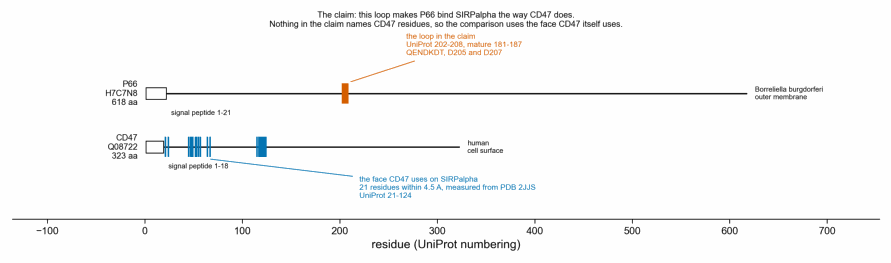

In [2]:
accessions = pl.read_csv(DATA / "01_accessions.csv")
numbering = pl.read_csv(DATA / "01_loop_numbering.csv")
print("Accessions resolved live from UniProt by gene and taxon:")
print(accessions)
print("\nThe paper's mature numbering mapped onto the UniProt entry:")
print(numbering)
show("276h_claim_diagram", aspect=0.28)

**Figure 276h.** The claim as a picture: which stretch of which protein, and against what.
`figures/276h_claim_diagram.png`. Each protein is a line with open boxes for its UniProt
features, the way InterPro draws one. Vermillion is the P66 loop the claim names; blue is
the CD47 face measured in section 2. Nothing has been measured yet at this point; the
figure only says what the comparison will be between.

## 1. How much of P66's model can be trusted

A comparison of shapes is only as good as the shapes. P66 has no experimental structure, so
every comparison below rests on an AlphaFold model, and the model's own confidence decides
how much any of it is worth. pLDDT is AlphaFold's per-residue confidence on a 0-100 scale;
AlphaFold calls anything under 50 "very low", meaning the residue's position should not be
relied on at all.

This is the single most important number in the notebook, so it comes first.

Models used, at the version the AlphaFold API reported today:
shape: (2, 6)
┌─────────┬──────────────┬─────────┬────────────────────┬────────────┬───────────────┐
│ protein ┆ entry_id     ┆ version ┆ all_versions       ┆ mean_plddt ┆ model_created │
│ ---     ┆ ---          ┆ ---     ┆ ---                ┆ ---        ┆ ---           │
│ str     ┆ str          ┆ i64     ┆ str                ┆ f64        ┆ str           │
╞═════════╪══════════════╪═════════╪════════════════════╪════════════╪═══════════════╡
│ P66     ┆ AF-H7C7N8-F1 ┆ 6       ┆ [3, 4, 5, 6]       ┆ 29.0       ┆ 2022-06-01    │
│ CD47    ┆ AF-Q08722-F1 ┆ 6       ┆ [1, 2, 3, 4, 5, 6] ┆ 86.31      ┆ 2025-08-01    │
└─────────┴──────────────┴─────────┴────────────────────┴────────────┴───────────────┘

Confidence summary:
shape: (1, 5)
┌──────────────────────────┬────────────────────────────┬──────────────────────┬───────────────────────┬─────────────────────────────┐
│ experimental_p66_entries ┆ n_experimental_p66_entries ┆ 

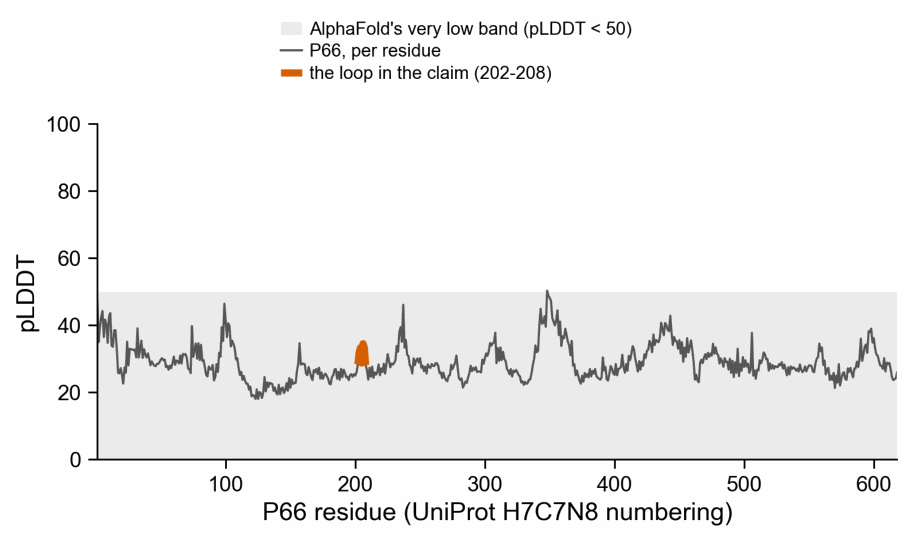

In [3]:
conf = pl.read_csv(DATA / "02_model_confidence_summary.csv")
models = pl.read_csv(DATA / "02_alphafold_models.csv")
plddt = pl.read_csv(DATA / "02_p66_plddt.csv")
start, end = int(numbering["full_start"][0]), int(numbering["full_end"][0])
loop_plddt = plddt.filter(pl.col("full_position").is_between(start, end))

print("Models used, at the version the AlphaFold API reported today:")
print(
    models.select(
        "protein", "entry_id", "version", "all_versions", "mean_plddt", "model_created"
    )
)
print("\nConfidence summary:")
print(conf)
print(f"\nThe loop, residue by residue (UniProt {start}-{end}):")
print(loop_plddt)
show("276a_p66_model_confidence")

**Figure 276a.** P66's model confidence along the chain, with the claimed loop marked.
`figures/276a_p66_model_confidence.png`.

**How to read it.** The grey band is AlphaFold's "very low" region. The whole P66 trace sits
inside it.

**What it says.** The AlphaFold model of P66 has a mean pLDDT of 29.0, the number AlphaFold
itself reports for the entry, and 99.8% of its 618 residues are below 50. The loop in the
claim is no exception: mean 31.2, range 28.1 to 34.5. The human CD47 model, fetched the
same way in the same run, has a mean pLDDT of 86.3, so this is a property of the P66 model
and not of how the files are being read. A search of the PDB found no experimental
structure of P66 at all.

The model is not formless, though: 42% of its residues are called β-strand from the
backbone geometry (section 5), which is what a β-barrel should look like, and section 4
shows Foldseek recovering outer-membrane β-barrels from it. Low confidence here means the
details cannot be trusted, not that the file is noise.

This weakens every structural comparison below, and it weakens them in both directions. A
model this uncertain cannot show that P66 resembles CD47, and it also cannot firmly show
that it does not. Section 8 returns to this as the strongest argument against the result.

## 2. CD47's SIRPα-binding face, measured rather than quoted

Rather than copy a residue list out of a paper, the face is measured from a crystal
structure of the two proteins together. RCSB was searched for CD47 / SIRPα complexes and
the entries ranked by resolution; entries whose own description calls a chain engineered,
high-affinity or a variant were set aside, because a mutant interface is not the wild-type
face the claim is about.

The face is defined as the CD47 residues with any heavy atom within 4.5 Å of any heavy atom
of SIRPα. Both CD47 copies in the crystal were tried against both SIRPα copies, and the
pair with the most contacts is the one reported; the others are crystal packing.

RCSB hits, best resolution first:
shape: (13, 7)
┌────────┬─────────────────────┬────────┬──────────┬───────────────┬────────────────────┬─────────────────────────────────┐
│ pdb_id ┆ resolution_angstrom ┆ method ┆ has_cd47 ┆ has_sirpalpha ┆ engineered_partner ┆ title                           │
│ ---    ┆ ---                 ┆ ---    ┆ ---      ┆ ---           ┆ ---                ┆ ---                             │
│ str    ┆ f64                 ┆ str    ┆ bool     ┆ bool          ┆ bool               ┆ str                             │
╞════════╪═════════════════════╪════════╪══════════╪═══════════════╪════════════════════╪═════════════════════════════════╡
│ 6LYC   ┆ 1.36                ┆ X-ray  ┆ false    ┆ true          ┆ false              ┆ Crystal structure of the NOD S… │
│ 6NMT   ┆ 1.83                ┆ X-ray  ┆ false    ┆ true          ┆ true               ┆ Non-Blocking Fab 3 anti-SIRP-a… │
│ 2JJS   ┆ 1.85                ┆ X-ray  ┆ true     ┆ true          ┆ false         

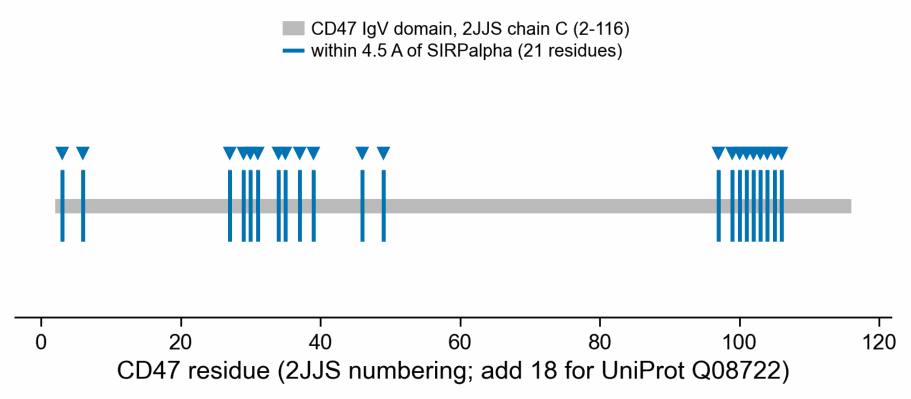

In [4]:
hits = pl.read_csv(DATA / "03_rcsb_search.csv")
chosen = pl.read_csv(DATA / "03_chosen_complex.csv")
face = pl.read_csv(DATA / "04_cd47_sirpalpha_face.csv")
domain = pl.read_csv(DATA / "05_cd47_igv_domain.csv")

print("RCSB hits, best resolution first:")
print(
    hits.select(
        "pdb_id",
        "resolution_angstrom",
        "method",
        "has_cd47",
        "has_sirpalpha",
        "engineered_partner",
        "title",
    )
)
print("\nThe entry used:")
print(
    chosen.select(
        "pdb_id",
        "title",
        "method",
        "resolution_angstrom",
        "cd47_chains",
        "sirpalpha_chains",
    )
)
print("\nThe CD47 chain taken as the IgV domain:")
print(domain)
print(f"\nThe binding face, {face.height} CD47 residues within 4.5 A of SIRPalpha:")
print(face)
show("276e_cd47_binding_face_map")

**Figure 276e.** Where the face residues sit along CD47's IgV domain.
`figures/276e_cd47_binding_face_map.png`.

**What it says.** PDB 2JJS, human CD47 with human SIRPα at 1.85 Å
([Hatherley et al. 2008](https://doi.org/10.1016/j.molcel.2008.05.026)), chain C against
chain A. 21 CD47 residues lie within 4.5 Å of SIRPα, in 11 separate runs along the chain,
the longest being 2JJS 99-106 (UniProt 117-124), 8 residues. The closest contact is 2.59 Å.
The face is not one flat patch but the N-terminus plus several loops at one end of the
domain, which is what the Hatherley paper describes.

[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96) measured the same face
from the same entry at a 4 Å cutoff and found 20 residues with a run at UniProt 115-124.
The two agree: the looser cutoff here adds one residue.

## 3. Comparison 1, the whole fold

US-align ([Zhang et al. 2022](https://doi.org/10.1038/s41592-022-01585-1)) aligns P66's
whole AlphaFold model against CD47's IgV domain. TM-score runs from 0 to 1 and depends on
which structure it is divided by, so both are reported; with a 618-residue query against a
115-residue domain, only the normalisation by CD47 is interpretable, and that is the one
quoted. TM-score at or above 0.5 is the usual line for "the same fold".

**The background.** 20 domains were drawn at random, with a fixed seed, from the 239
immunoglobulin-like domains of SCOPe 2.08 superfamily b.1.1 in the ASTRAL 40% set, which
holds one domain per 40%-identity cluster, so they are unrelated to each other as well as
to CD47. Each is aligned to the same CD47 domain the same way. These are the scores a
genuine immunoglobulin relative of CD47 earns.

The claimed pair, US-align:
shape: (1, 7)
┌─────────────────────────────────┬─────────────────────┬──────────────────────┬────────────────┬───────────────┬──────────────┬───────────────┐
│ comparison                      ┆ tm_score_norm_query ┆ tm_score_norm_target ┆ aligned_length ┆ rmsd_angstrom ┆ query_length ┆ target_length │
│ ---                             ┆ ---                 ┆ ---                  ┆ ---            ┆ ---           ┆ ---          ┆ ---           │
│ str                             ┆ f64                 ┆ f64                  ┆ i64            ┆ f64           ┆ i64          ┆ i64           │
╞═════════════════════════════════╪═════════════════════╪══════════════════════╪════════════════╪═══════════════╪══════════════╪═══════════════╡
│ P66 AlphaFold model vs CD47 Ig… ┆ 0.09118             ┆ 0.34233              ┆ 68             ┆ 4.34          ┆ 618          ┆ 115           │
└─────────────────────────────────┴─────────────────────┴──────────────────────┴────────

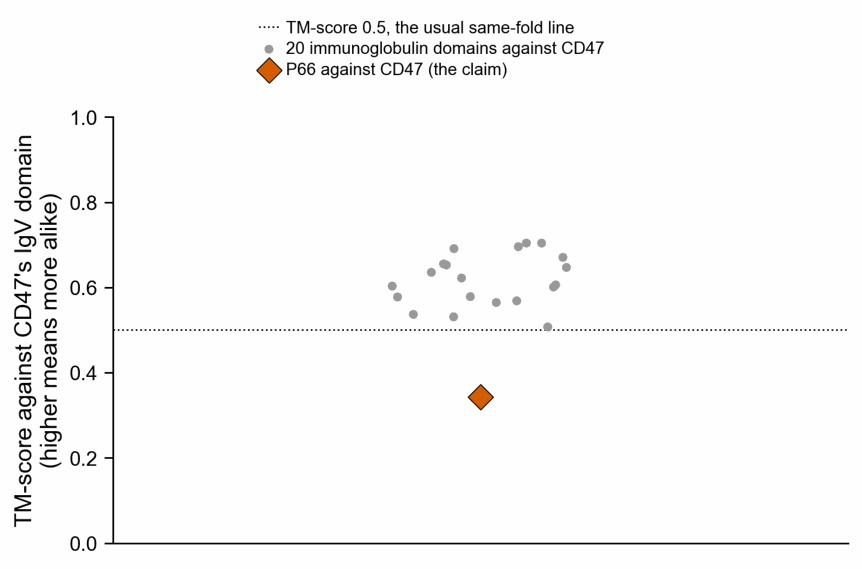

In [5]:
claimed = pl.read_csv(DATA / "05_wholefold_claimed.csv")
bg = pl.read_csv(DATA / "05_wholefold_background.csv")
pool = pl.read_csv(DATA / "05_ig_superfamily_pool.csv")

print("The claimed pair, US-align:")
print(claimed)
print(
    f"\nBackground: {bg.height} immunoglobulin domains drawn from "
    f"{pool.height} in SCOPe b.1.1, ASTRAL-40:"
)
print(
    bg.select(
        "comparison",
        "sccs",
        "tm_score_norm_target",
        "aligned_length",
        "rmsd_angstrom",
        "query_length",
        "description",
    )
)
claim_tm = claimed["tm_score_norm_target"][0]
print(f"\nClaimed pair TM-score (normalised by CD47): {claim_tm}")
print(
    f"Background median {bg['tm_score_norm_target'].median():.3f}, "
    f"range {bg['tm_score_norm_target'].min():.3f} to "
    f"{bg['tm_score_norm_target'].max():.3f}"
)
print(
    f"Background domains scoring above the claimed pair: "
    f"{(bg['tm_score_norm_target'] > claim_tm).sum()} of {bg.height}"
)
show("276c_wholefold_tmscore_background")

**Figure 276c.** The claimed pair against the 20-domain background.
`figures/276c_wholefold_tmscore_background.png`.

**What it says.** P66 against CD47's IgV domain scores TM-score 0.342 normalised by CD47,
over 68 aligned residues at 4.34 Å RMSD. That is below 0.5, so not the same fold by the
usual line. All 20 immunoglobulin domains score higher, from 0.507 to 0.704, median 0.614,
and the lowest of them still clears 0.5.

**The decision.** The claimed pair does not beat the background. It is not merely at the
bottom of the range; it is outside it, below every one of 20.

## 4. Comparison 2, Foldseek

Foldseek ([van Kempen et al. 2023](https://doi.org/10.1038/s41587-023-01773-0), version
10.941cd33) searches P66's model twice: against the whole PDB, using Foldseek's own PDB100
database built 2025-01-01, and directly against CD47's AlphaFold model. The second search
uses `--exhaustive-search` with no E-value ceiling, which forces an alignment to be
reported whether or not one is worth reporting, so that the pair cannot simply fall below
a threshold and vanish.

**The control that makes the PDB search mean something.** 2JJS is in the database. All four
of its chains are there, so if CD47 is absent from P66's hit list that is a real negative
and not a gap in the database.

P66 against the PDB, 12 strongest hits:
shape: (12, 11)
┌───────────────────────┬──────────────────┬────────┬──────┬───┬────────┬──────┬────────┬───────┐
│ query                 ┆ target           ┆ evalue ┆ bits ┆ … ┆ tstart ┆ tend ┆ alnlen ┆ prob  │
│ ---                   ┆ ---              ┆ ---    ┆ ---  ┆   ┆ ---    ┆ ---  ┆ ---    ┆ ---   │
│ str                   ┆ str              ┆ f64    ┆ i64  ┆   ┆ i64    ┆ i64  ┆ i64    ┆ f64   │
╞═══════════════════════╪══════════════════╪════════╪══════╪═══╪════════╪══════╪════════╪═══════╡
│ AF-H7C7N8-F1-model_v6 ┆ 5o68-assembly2_D ┆ 0.128  ┆ 45   ┆ … ┆ 36     ┆ 241  ┆ 337    ┆ 0.326 │
│ AF-H7C7N8-F1-model_v6 ┆ 1bp1-assembly1_A ┆ 0.128  ┆ 26   ┆ … ┆ 18     ┆ 382  ┆ 481    ┆ 0.063 │
│ AF-H7C7N8-F1-model_v6 ┆ 5o68-assembly3_G ┆ 0.1349 ┆ 45   ┆ … ┆ 36     ┆ 241  ┆ 341    ┆ 0.326 │
│ AF-H7C7N8-F1-model_v6 ┆ 5o65-assembly1_C ┆ 0.1581 ┆ 37   ┆ … ┆ 38     ┆ 241  ┆ 342    ┆ 0.164 │
│ AF-H7C7N8-F1-model_v6 ┆ 2bi0-assembly1_A ┆ 0.217  ┆ 22   ┆ …

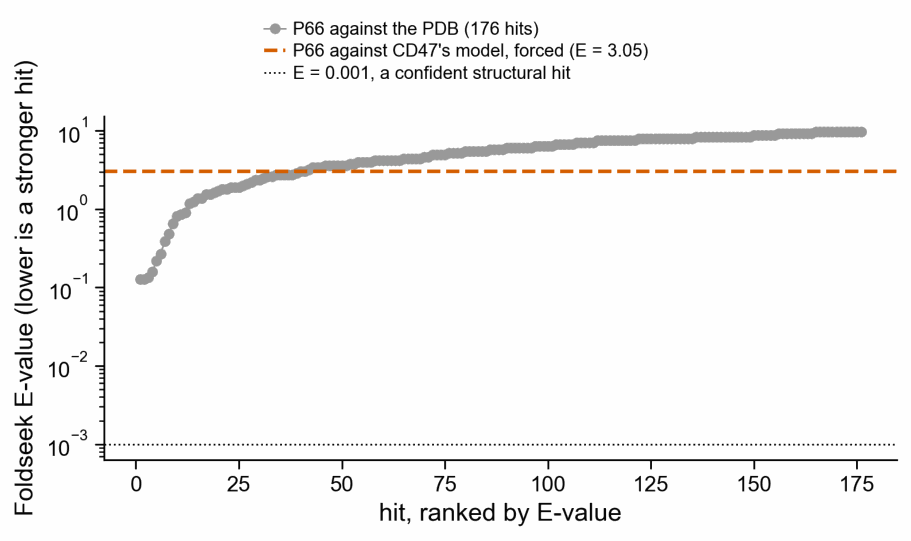

In [6]:
pdb_hits = pl.read_csv(DATA / "06_foldseek_vs_pdb.csv")
pair_hit = pl.read_csv(DATA / "06_foldseek_vs_cd47_model.csv")

print("P66 against the PDB, 12 strongest hits:")
print(pdb_hits.sort("evalue").head(12))
print(
    f"\n{pdb_hits.height} hits in total; best E-value "
    f"{pdb_hits['evalue'].min()}; hits below E = 0.001: "
    f"{(pdb_hits['evalue'] < 0.001).sum()}"
)
cd47_entries = pdb_hits.filter(
    pl.col("target").str.contains("(?i)2jjs|4cmm|2jjt|4kjy|7ygg")
)
print(f"CD47 / SIRPalpha entries among the hits: {cd47_entries.height}")
print("\nP66 against CD47's AlphaFold model, forced:")
print(pair_hit)
show("276f_foldseek_p66_vs_pdb")

**Figure 276f.** Foldseek's E-values for P66 against the PDB, ranked.
`figures/276f_foldseek_p66_vs_pdb.png`.

**What it says.** Foldseek returns 176 hits for P66 in the PDB. Not one reaches E = 0.001,
and the best is E = 0.128. The strongest hits are bacterial outer-membrane β-barrels: 5o68
and 5o65, the *Pseudomonas* functional amyloid secretion protein FapF, and 1thq, the outer
membrane enzyme PagP. That is the right answer for what P66 is, and it shows the search is
working rather than returning noise. No CD47 or SIRPα entry appears anywhere in the list,
although 2JJS is in the database.

Forced against CD47's model, the single reported alignment has E = 3.05, probability 0.00,
and covers P66 526-547 against CD47 111-126: 22 residues at the far end of P66, nowhere
near the loop at 202-208. The alignment's local TM-score of 0.579 is measured over those 22
residues only and says nothing about the two proteins.

## 5. Comparison 3, the loop against the face

The binding face is 11 separate runs, not one stretch, so "superpose the loop on the face"
needs a definite meaning. Here it is: the loop's 7 residues are superposed, backbone atoms
N, CA, C and O in sequence order, onto every run of 7 consecutive CD47 residues that
includes at least one face residue, and the best RMSD over those windows is reported.

**The background.** 10 other loops of P66, each 7 residues long, each a run of coil, none
overlapping the claimed loop, drawn at random with the same fixed seed. Coil is assigned
from CA geometry, because DSSP is not installed on this machine; the criteria are the
CA-distance ranges P-SEA uses, and **I cannot verify a citation for this claim** — a PubMed
search for the P-SEA paper returned nothing. Each background loop gets the same treatment
against the same windows.

Two things to know about this background before reading the result. The model is 53% coil,
42% strand and 5% helix, so the coil runs the background is drawn from are real coil
between strands and not one long disordered chain; that also fits Foldseek calling P66 a
β-barrel in section 4. But two pairs of the ten windows overlap each other (117-123 with
122-128, and 563-569 with 565-571), so there are eight independent stretches rather than
ten, and the background spread is slightly narrower than ten separate draws would give.

The claimed loop on every face window, best first:
shape: (10, 5)
┌──────────────┬────────────┬────────────────────────┬──────────────────┬──────────────┐
│ window_start ┆ window_end ┆ backbone_rmsd_angstrom ┆ n_backbone_atoms ┆ loop         │
│ ---          ┆ ---        ┆ ---                    ┆ ---              ┆ ---          │
│ i64          ┆ i64        ┆ f64                    ┆ i64              ┆ str          │
╞══════════════╪════════════╪════════════════════════╪══════════════════╪══════════════╡
│ 29           ┆ 35         ┆ 1.912462               ┆ 28               ┆ claimed loop │
│ 25           ┆ 31         ┆ 1.942834               ┆ 28               ┆ claimed loop │
│ 27           ┆ 33         ┆ 2.001426               ┆ 28               ┆ claimed loop │
│ 33           ┆ 39         ┆ 2.103826               ┆ 28               ┆ claimed loop │
│ 100          ┆ 106        ┆ 2.12774                ┆ 28               ┆ claimed loop │
│ 24           ┆ 30         ┆ 2.22591       

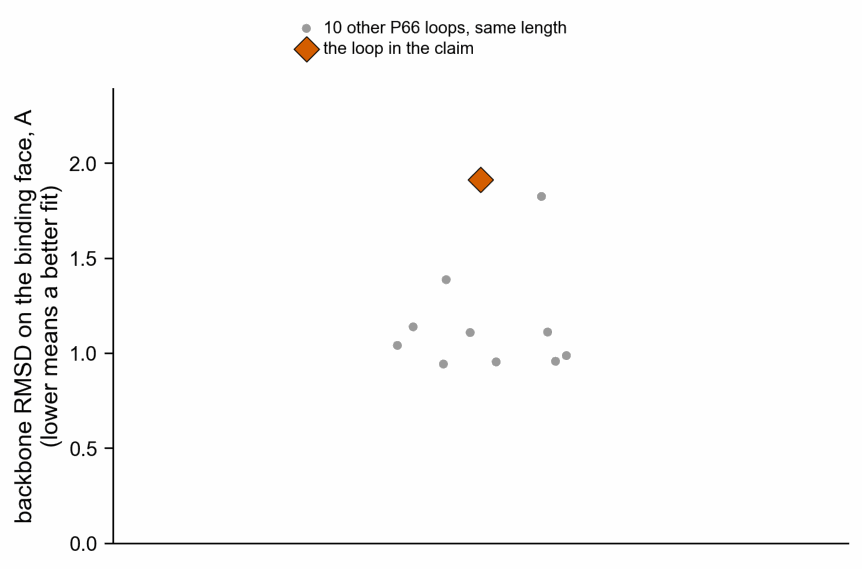

In [7]:
claimed_rmsd = pl.read_csv(DATA / "07_claimed_loop_vs_face.csv")
bg_loops = pl.read_csv(DATA / "07_background_loops_vs_face.csv")
sup = pl.read_csv(DATA / "09_superposition_summary.csv")

print("The claimed loop on every face window, best first:")
print(claimed_rmsd.head(10))
best = claimed_rmsd.sort("backbone_rmsd_angstrom").row(0, named=True)
print(
    f"\nBest: {best['backbone_rmsd_angstrom']:.2f} A on CD47 "
    f"{best['window_start']}-{best['window_end']}"
)
print(f"\nBackground, {bg_loops.height} other P66 loops of the same length:")
print(bg_loops)
print(
    f"\nBackground median {bg_loops['backbone_rmsd_angstrom'].median():.2f} A, "
    f"best {bg_loops['backbone_rmsd_angstrom'].min():.2f} A"
)
print(
    f"Background loops fitting better than the claimed loop: "
    f"{(bg_loops['backbone_rmsd_angstrom'] < best['backbone_rmsd_angstrom']).sum()}"
    f" of {bg_loops.height}"
)
show("276d_loop_to_face_rmsd_background")

**Figure 276d.** The claimed loop against 10 other P66 loops.
`figures/276d_loop_to_face_rmsd_background.png`.

**What it says.** The claimed loop's best fit is 1.91 Å backbone RMSD, on CD47 29-35. All 10
other P66 loops fit better, median 1.07 Å, best 0.94 Å.

**The decision.** The claimed loop does not beat the background; it is the worst of the
eleven. Read plainly, a 7-residue backbone can be laid onto a 7-residue backbone at about
1 Å whatever the two are, and the claimed loop does not even manage the ordinary amount.

Where the loop actually lands once the two proteins are superposed:
shape: (1, 9)
┌────────────────────────────────┬────────────────────────────────┬─────────────────────────────────┬─────────────────────┬───┬────────────────┬───────────────┬──────────────┬───────────────┐
│ loop_to_face_centroid_angstrom ┆ cd47_igv_widest_ca_ca_angstrom ┆ comparison                      ┆ tm_score_norm_query ┆ … ┆ aligned_length ┆ rmsd_angstrom ┆ query_length ┆ target_length │
│ ---                            ┆ ---                            ┆ ---                             ┆ ---                 ┆   ┆ ---            ┆ ---           ┆ ---          ┆ ---           │
│ f64                            ┆ f64                            ┆ str                             ┆ f64                 ┆   ┆ i64            ┆ f64           ┆ i64          ┆ i64           │
╞════════════════════════════════╪════════════════════════════════╪═════════════════════════════════╪═════════════════════╪═══╪════════════════╪══════

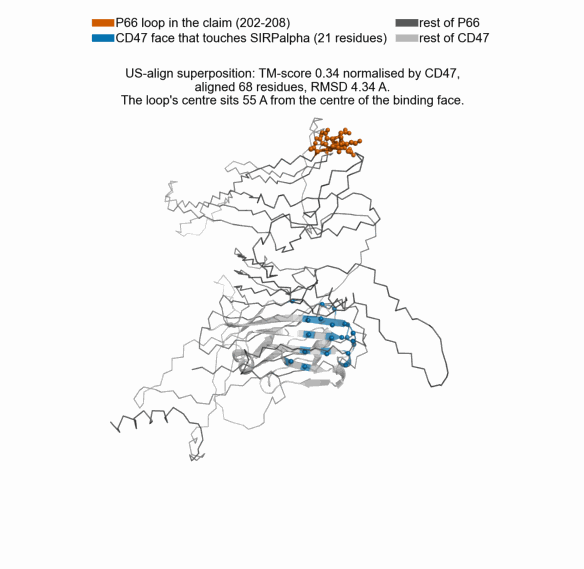

In [8]:
print("Where the loop actually lands once the two proteins are superposed:")
print(sup)
show("276b_p66_cd47_superposition")

**Figure 276b.** The two structures superposed by US-align, with the loop and the face
coloured. `figures/276b_p66_cd47_superposition.png`.

**How to read it.** Vermillion is the P66 loop in the claim, blue is CD47's SIRPα-binding
face, dark grey is the rest of P66 as a thin trace, light grey is the rest of CD47.

**What it says.** In the best whole-fold superposition the two structures have, the centre
of the loop sits 55 Å from the centre of the binding face. CD47's IgV domain is only 45 Å across at its widest,
measured here as the longest CA-to-CA distance in it, so the loop does not land on the
wrong part of the face: it lands off the domain entirely. The thin grey trace wandering across the picture is the rest of P66, drawn
as it is modelled, and it is a fair picture of what a mean pLDDT of 29 looks like.

## 6. What kmerseek already says here, across every alphabet

This is a negative result and is kept as one.
[PR 96](https://github.com/seanome/2024-kmerseek-analysis/pull/96),
[notebook 245](./245_p66_cd47_pair_coordinates.ipynb), mapped every k-mer P66 and CD47
share onto both sequences: **none of the 326 shared k-mers touches the P66 loop**. That
sweep was not only the two-letter alphabets. It covered **16 alphabets over 27 settings**,
from `protein20`-adjacent `hsdm17` and `mmseqs12` down through `sdm12`, `funcgroups8`,
`gbmr7`, `dayhoff6`, `wwmj5`, `polarity4` and `gbmr4` to the HP family. The count is zero
in every one of them.

So the question is what the larger alphabets see there, and the answer has two parts.

**Part one: eight alphabets write the loop as one repeated class, not six.** The loop is
`QENDKDT`, seven polar residues. All six two-letter alphabets write it as one letter, and
so do `hp_lehninger_hpc3` with 3 classes and `gbmr4` with 4, because `gbmr4` pools
`ADKERNTSQ` into a single class that swallows all seven residues. In those eight a k-mer on
the loop carries no pattern at all: it cannot be told from any other polar stretch of the
same length in any protein.

**Part two: in the eleven alphabets where the loop is a varied string, its k-mers still do
not exist in CD47.** `polarity4` writes it `BCBCDCB`, `funcgroups8` writes it `FGFGHGB`,
`protein20` of course keeps all seven residues distinct. A varied string could carry a
signal, so a class string alone cannot settle it; both proteins have to be encoded and
looked at. Doing that for all 19 alphabets in the repo's table at every k from 5 to 25:
at **all 27 settings PR 96 searched, zero k-mers covering the loop occur anywhere in
CD47**, and in 9 of the 11 varied alphabets none occurs at any k in that range. The two
exceptions are worth naming rather than hiding: `polarity4` has exactly one, and `gbmr7`
two, all at k = 5, and section 6b prints them residue by residue.

**This changes how PR 96's number should be read.** That notebook reported 0 observed
against 8.5 expected, binomial p = 0.00035, and called it "fewer than chance". The expected
count assumes a shared k-mer was available to land on the loop by chance. None was. The
zero is forced by the encoding and by which settings were searched, not evidence that
something avoids the loop. PR 96 said its pooled test should be read as a direction rather
than a p-value to defend, and this is why.

A loop k-mer does reach CD47, but only at k of 13 or less and only in the alphabets that
write the loop as one repeated class, where a run of identical letters matches any polar
stretch. That is a match without information, and PR 96 searched no setting there.

**What this does and does not support.** Convergent mimicry is the hypothesis that two
unrelated sequences arrived at the same shape. It predicts no sequence signal, so a zero
here is consistent with mimicry being real. It is equally consistent with mimicry not being
real. On this evidence it supports neither, and after the stronger reading above it supports
neither even weakly: no alphabet in the sweep could have found anything on this loop. The
three structural comparisons are what can separate the two, and they point the other way.

The loop in every alphabet. Grid letters are class numbers relabelled
A, B, C..., not residues; in protein20 that relabelling is one-to-one.
shape: (19, 5)
┌──────────────────────────┬───────────┬───────────────────┬────────────────────────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ loop_class_string ┆ n_distinct_classes_in_loop ┆ found_over_k_5_to_25 │
│ ---                      ┆ ---       ┆ ---               ┆ ---                        ┆ ---                  │
│ str                      ┆ i64       ┆ str               ┆ i64                        ┆ i64                  │
╞══════════════════════════╪═══════════╪═══════════════════╪════════════════════════════╪══════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ BBBBBBB           ┆ 1                          ┆ 36                   │
│ hp_lehninger2            ┆ 2         ┆ BBBBBBB           ┆ 1                          ┆ 43                   │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ BBBBBBB     

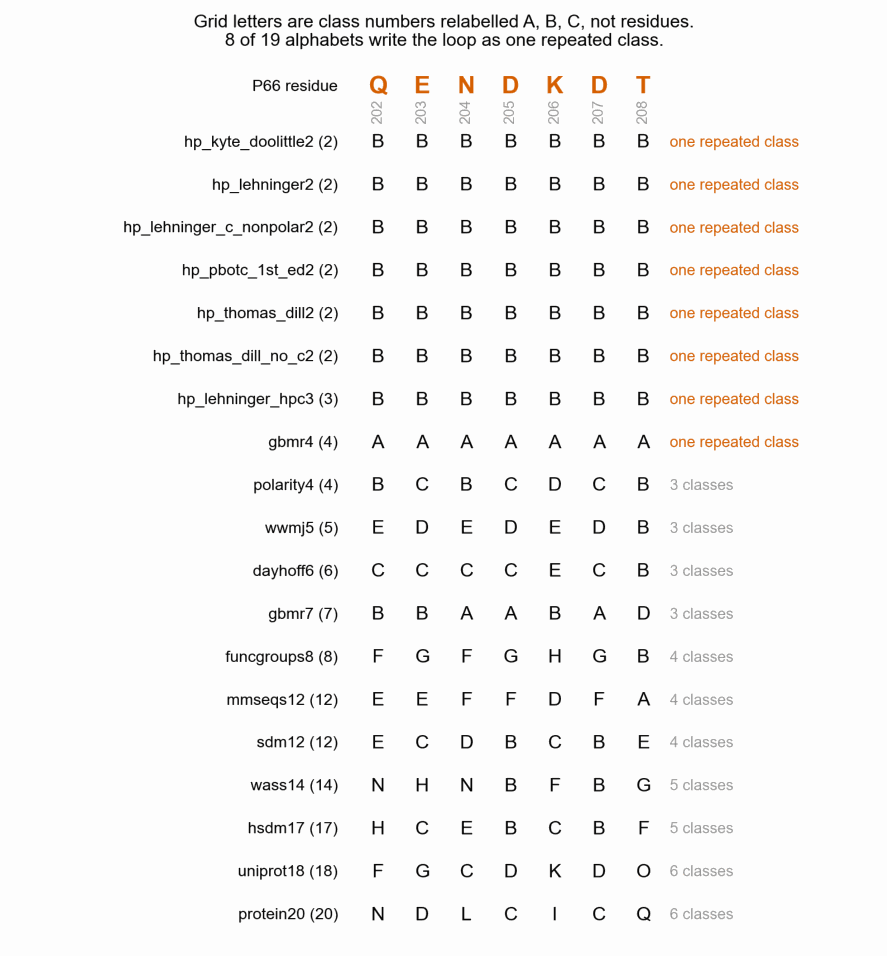

In [9]:
reach = pl.read_csv(DATA / "09_loop_kmer_reach_all_alphabets.csv")
per_alphabet = (
    reach.group_by("alphabet", "n_classes")
    .agg(
        pl.col("loop_class_string").first(),
        pl.col("n_distinct_classes_in_loop").first(),
        pl.col("n_covering_kmers_found_in_cd47").sum().alias("found_over_k_5_to_25"),
    )
    .sort("n_classes", "alphabet")
)
print("The loop in every alphabet. Grid letters are class numbers relabelled")
print("A, B, C..., not residues; in protein20 that relabelling is one-to-one.")
print(per_alphabet)
n_uniform = (per_alphabet["n_distinct_classes_in_loop"] == 1).sum()
print(
    f"\nAlphabets writing the loop as one repeated class: "
    f"{n_uniform} of {per_alphabet.height}"
)
print(
    f"Varied alphabets with no loop k-mer in CD47 at any k from 5 to 25: "
    f"{per_alphabet.filter((pl.col('n_distinct_classes_in_loop') > 1) & (pl.col('found_over_k_5_to_25') == 0)).height}"
    f" of {per_alphabet.filter(pl.col('n_distinct_classes_in_loop') > 1).height}"
)
reachable = reach.filter(pl.col("n_covering_kmers_found_in_cd47") > 0)
print(
    f"Highest k at which any loop k-mer occurs in CD47: {reachable['ksize'].max()}, "
    f"in {sorted(reachable.filter(pl.col('ksize') == reachable['ksize'].max())['alphabet'].to_list())}"
)
show("276g_loop_class_strings_all_alphabets", aspect=1.05)

**Figure 276g.** The loop written out in every alphabet, smallest to largest.
`figures/276g_loop_class_strings_all_alphabets.png`. The grid letters are class numbers
relabelled A, B, C and are not residues; the vermillion row at the top is the real
sequence.

Every setting PR 96 searched, and whether a loop k-mer existed to be found:
shape: (27, 4)
┌──────────────────────────┬───────┬───────────────────────────┬────────────────────────────────┐
│ alphabet                 ┆ ksize ┆ n_p66_kmers_covering_loop ┆ n_covering_kmers_found_in_cd47 │
│ ---                      ┆ ---   ┆ ---                       ┆ ---                            │
│ str                      ┆ i64   ┆ i64                       ┆ i64                            │
╞══════════════════════════╪═══════╪═══════════════════════════╪════════════════════════════════╡
│ dayhoff6                 ┆ 7     ┆ 13                        ┆ 0                              │
│ funcgroups8              ┆ 6     ┆ 12                        ┆ 0                              │
│ funcgroups8              ┆ 7     ┆ 13                        ┆ 0                              │
│ gbmr4                    ┆ 10    ┆ 16                        ┆ 0                              │
│ gbmr7                    

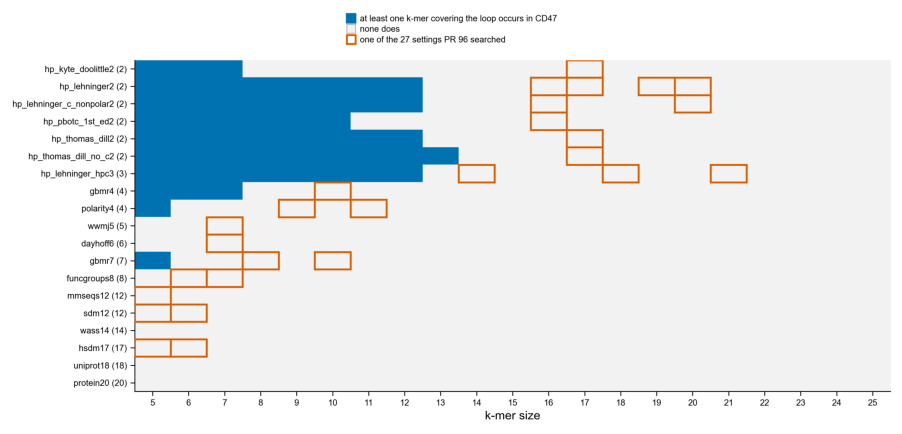

In [10]:
print("Every setting PR 96 searched, and whether a loop k-mer existed to be found:")
pr96 = [
    ("dayhoff6", 7),
    ("funcgroups8", 6),
    ("funcgroups8", 7),
    ("gbmr4", 10),
    ("gbmr7", 8),
    ("gbmr7", 10),
    ("hp_kyte_doolittle2", 17),
    ("hp_lehninger2", 16),
    ("hp_lehninger2", 17),
    ("hp_lehninger2", 19),
    ("hp_lehninger2", 20),
    ("hp_lehninger_c_nonpolar2", 16),
    ("hp_lehninger_c_nonpolar2", 20),
    ("hp_lehninger_hpc3", 14),
    ("hp_lehninger_hpc3", 18),
    ("hp_lehninger_hpc3", 21),
    ("hp_pbotc_1st_ed2", 16),
    ("hp_thomas_dill2", 17),
    ("hp_thomas_dill_no_c2", 17),
    ("hsdm17", 5),
    ("hsdm17", 6),
    ("mmseqs12", 5),
    ("polarity4", 9),
    ("polarity4", 11),
    ("sdm12", 5),
    ("sdm12", 6),
    ("wwmj5", 7),
]
keys = [f"{a}@{k}" for a, k in pr96]
swept = reach.filter(
    pl.concat_str(
        [pl.col("alphabet"), pl.col("ksize").cast(pl.Utf8)], separator="@"
    ).is_in(keys)
)
print(
    swept.select(
        "alphabet",
        "ksize",
        "n_p66_kmers_covering_loop",
        "n_covering_kmers_found_in_cd47",
    ).sort("alphabet", "ksize")
)
print(
    f"\n{swept.height} settings; P66 k-mers covering the loop: "
    f"{swept['n_p66_kmers_covering_loop'].sum()}; of those, occurring in CD47: "
    f"{swept['n_covering_kmers_found_in_cd47'].sum()}"
)
show("276i_loop_kmer_reach_by_alphabet_and_k", aspect=0.47)

**Figure 276i.** Whether any k-mer covering the loop occurs in CD47, for every alphabet and
k. `figures/276i_loop_kmer_reach_by_alphabet_and_k.png`.

**How to read it.** One cell per alphabet and k. Blue means at least one of P66's
loop-covering k-mers occurs somewhere in CD47, so a shared k-mer on the loop was possible
there. Grey means none does, so no search at that setting could have found one whatever the
biology. A vermillion outline marks one of the 27 settings PR 96 searched.

**What it says.** Every vermillion box sits on a grey cell. The blue region is confined to
low k in the alphabets that write the loop as one repeated class, and PR 96 searched none of
it. Its zero is therefore a statement about where it looked, not about the loop.

## 6b. The shared k-mers on the loop, printed out

A count is not enough to judge a match. Every shared k-mer that covers the loop, in every
alphabet, written as the two spans with their residues. Only three of them are in an
alphabet where the loop is a varied string, and all three are at k = 5, which is shorter
than any setting in the project.

1108 shared k-mers cover the loop in total; 1105 are in the 8 alphabets that write it as one repeated class.

The 3 in an alphabet where the loop is a varied string:
shape: (3, 11)
┌───────────┬───────┬───────────┬─────────┬───┬───────────────┬──────────────┬──────────────────────┬───────────────────────┐
│ alphabet  ┆ ksize ┆ p66_start ┆ p66_end ┆ … ┆ cd47_residues ┆ class_string ┆ n_identical_residues ┆ loop_residues_covered │
│ ---       ┆ ---   ┆ ---       ┆ ---     ┆   ┆ ---           ┆ ---          ┆ ---                  ┆ ---                   │
│ str       ┆ i64   ┆ i64       ┆ i64     ┆   ┆ str           ┆ str          ┆ i64                  ┆ str                   │
╞═══════════╪═══════╪═══════════╪═════════╪═══╪═══════════════╪══════════════╪══════════════════════╪═══════════════════════╡
│ gbmr7     ┆ 5     ┆ 199       ┆ 203     ┆ … ┆ NENIL         ┆ ABABB        ┆ 2                    ┆ 202,203               │
│ gbmr7     ┆ 5     ┆ 202       ┆ 206     ┆ … ┆ MMNDE         ┆

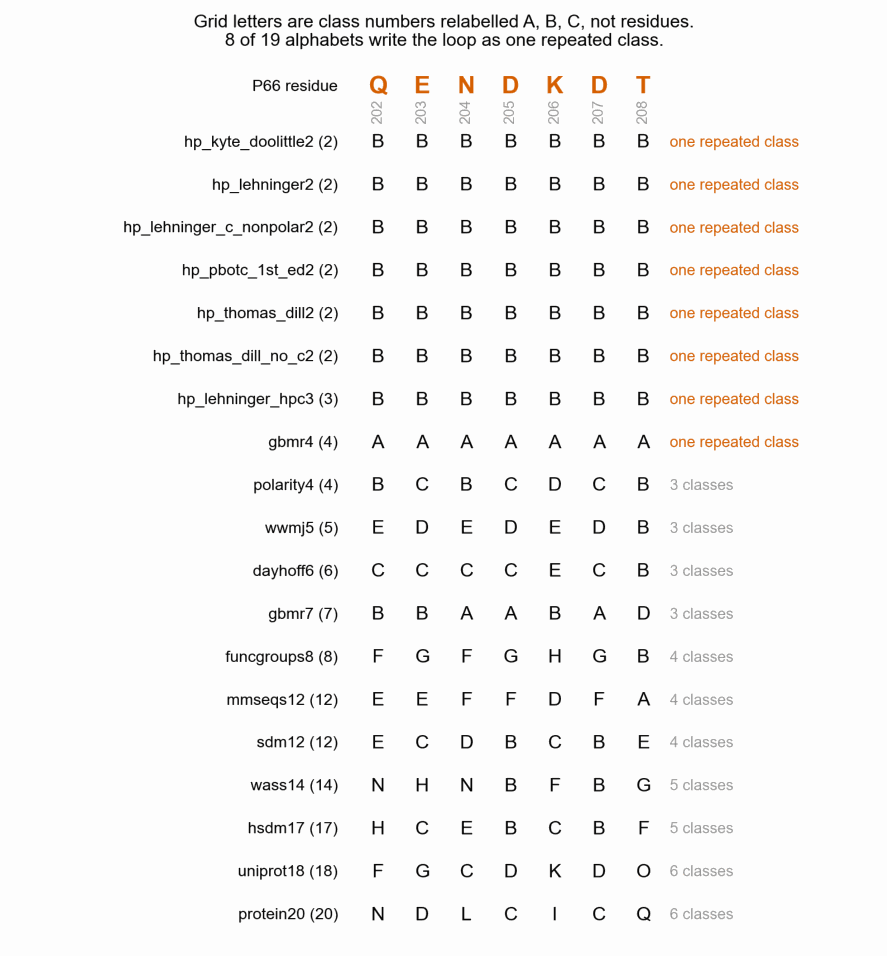

In [11]:
pairs = pl.read_csv(DATA / "10_loop_kmer_pairs.csv")
uniform = (
    pl.read_csv(DATA / "09_loop_kmer_reach_all_alphabets.csv")
    .filter(pl.col("n_distinct_classes_in_loop") == 1)["alphabet"]
    .unique()
    .to_list()
)
varied_pairs = pairs.filter(~pl.col("alphabet").is_in(uniform))
print(
    f"{pairs.height} shared k-mers cover the loop in total; "
    f"{pairs.height - varied_pairs.height} are in the "
    f"{len(uniform)} alphabets that write it as one repeated class."
)
print(f"\nThe {varied_pairs.height} in an alphabet where the loop is a varied string:")
print(
    varied_pairs.select(
        "alphabet",
        "ksize",
        "p66_start",
        "p66_end",
        "p66_residues",
        "cd47_start",
        "cd47_end",
        "cd47_residues",
        "class_string",
        "n_identical_residues",
        "loop_residues_covered",
    )
)
print("\nFor comparison, three from a uniform alphabet at the k where they stop:")
print(
    pairs.filter(pl.col("alphabet").is_in(uniform) & (pl.col("ksize") == 13))
    .select(
        "alphabet",
        "ksize",
        "p66_residues",
        "cd47_residues",
        "class_string",
        "n_identical_residues",
    )
    .head(3)
)
show("276g_loop_class_strings_all_alphabets", aspect=1.05)

**What it says.** In the eight alphabets that write the loop as one repeated class, k-mers
on the loop match CD47 freely up to k = 13, and the pairs show why that is worthless:
`DTPYNKTYQG` against `KSTVPTDFSS` is 0 identical residues out of 10. Both are polar runs
and the alphabet cannot tell them apart.

In the eleven where the loop is a varied string there are exactly three shared k-mers, all
at k = 5: two in `gbmr7` and one in `polarity4`. `funcgroups8` has none at any k from 5 to
25. The best of the three, `gbmr7` k = 5, puts P66 `QENDK` against CD47 `MMNDE` with 2
identical residues and does cover D205. k = 5 in a 7-class alphabet is about 14 bits, well
below anything this project searches at, and PR 96 swept `gbmr7` at k = 8 and 10.

## 6c. Seed-and-extend, which exact k-mers cannot do

Everything above tests exact k-mers, and exact matching has a hard floor: if no k-mer on
the loop exists in CD47, no amount of searching finds one. Seed-and-extend does not have
that floor. A seed that lands beside the loop extends across it, and the extension tolerates
mismatches. So the honest question is whether seed-and-extend reaches the loop, and whether
what it finds there is better than chance.

`notebooks/seed_extend_utils.py` scores an alignment that already exists (notebook 232).
P66 and CD47 have no alignment, which is the whole difficulty, so
`scripts/nb276_seed_extend_loop.py` finds seeds by exact match in the reduced alphabet and
extends each along its own diagonal with X-drop, scoring +1 for a shared class and
-penalty otherwise, the same scheme that module uses. 11 alphabets x 4 seed lengths x 3
penalties = 132 settings. The eight alphabets that write the loop as one repeated class are
left out: there a seed matches every polar stretch, so covering the loop is guaranteed and
means nothing.

**The decision rule, before the numbers.** A hit counts only if it clears all four of:
beats shuffled CD47 after correcting for the 132 settings tried; survives a stricter null
that keeps CD47's neighbouring-residue frequencies, not only its composition; puts the CD47
side of the segment on residues that actually touch SIRPalpha; and earns its score on the
loop rather than on the residues beside it.

In [12]:
sweep = pl.read_csv(DATA / "11_seed_extend_loop.csv")
reach = sweep.filter(pl.col("reaches_loop"))
overlap = pl.read_csv(DATA / "13_seed_extend_face_overlap.csv")
follow = pl.read_csv(DATA / "12_seed_extend_followup.csv")
contrib = pl.read_csv(DATA / "14_seed_extend_loop_contribution.csv")

print(
    f"{reach.height} of {sweep.height} settings produce a segment covering the loop; "
    f"{reach.filter(pl.col('covers_both_aspartates')).height} cover both aspartates."
)
print(
    f"{reach.filter(pl.col('p_value_vs_shuffled_cd47') < 0.05).height} beat shuffled "
    f"CD47 at an uncorrected p < 0.05, against "
    f"{0.05 * sweep.height:.1f} expected from {sweep.height} tests by chance alone."
)
print("\nHow often the NULL also produces a loop-covering segment, by penalty:")
print(
    reach.group_by("penalty")
    .agg(
        pl.len().alias("settings_reaching"),
        pl.col("null_fraction_reaching_loop").mean().round(3).alias("mean_null_reach"),
        pl.col("score").max().alias("max_score"),
    )
    .sort("penalty")
)
print("\nDoes the CD47 side land on the face? Top of the table by face residues hit:")
print(
    overlap.select(
        "alphabet",
        "seed_length",
        "penalty",
        "score",
        "cd47_span",
        "fraction_in_ectodomain",
        "n_face_residues_touched",
        "covers_both_aspartates",
    ).head(10)
)

30 of 132 settings produce a segment covering the loop; 17 cover both aspartates.
4 beat shuffled CD47 at an uncorrected p < 0.05, against 6.6 expected from 132 tests by chance alone.

How often the NULL also produces a loop-covering segment, by penalty:
shape: (3, 4)
┌─────────┬───────────────────┬─────────────────┬───────────┐
│ penalty ┆ settings_reaching ┆ mean_null_reach ┆ max_score │
│ ---     ┆ ---               ┆ ---             ┆ ---       │
│ f64     ┆ u32               ┆ f64             ┆ f64       │
╞═════════╪═══════════════════╪═════════════════╪═══════════╡
│ 0.5     ┆ 16                ┆ 0.751           ┆ 62.5      │
│ 1.0     ┆ 7                 ┆ 0.811           ┆ 12.0      │
│ 2.0     ┆ 7                 ┆ 0.727           ┆ 6.0       │
└─────────┴───────────────────┴─────────────────┴───────────┘

Does the CD47 side land on the face? Top of the table by face residues hit:
shape: (10, 8)
┌───────────┬─────────────┬─────────┬───────┬───────────┬────────────────────────

**The big scores are runaway extensions, not matches.** At penalty 0.5 the longest segment
is 318 residues, the whole of CD47, and `polarity4` scores 46.5 against a null median of
50.5: below its own chance level. Those are the extension never stopping, not a similarity.
The settings worth testing are the ones with a modest score and a short segment.

The four that beat the uncorrected threshold, re-tested with 5_000 shuffles
of each kind. The Bonferroni threshold for 132 settings is p < 0.00038.
shape: (4, 9)
┌──────────┬───────────┬─────────────┬─────────┬───┬────────────────┬────────────────────┬────────────────────────┬────────────────────────────────┐
│ alphabet ┆ n_classes ┆ seed_length ┆ penalty ┆ … ┆ segment_length ┆ p_composition_null ┆ p_neighbour_pairs_null ┆ survives_bonferroni_both_nulls │
│ ---      ┆ ---       ┆ ---         ┆ ---     ┆   ┆ ---            ┆ ---                ┆ ---                    ┆ ---                            │
│ str      ┆ i64       ┆ i64         ┆ f64     ┆   ┆ i64            ┆ f64                ┆ f64                    ┆ bool                           │
╞══════════╪═══════════╪═════════════╪═════════╪═══╪════════════════╪════════════════════╪════════════════════════╪════════════════════════════════╡
│ hsdm17   ┆ 17        ┆ 4           ┆ 0.5     ┆ … ┆ 36             ┆ 0.0004             ┆ 0.

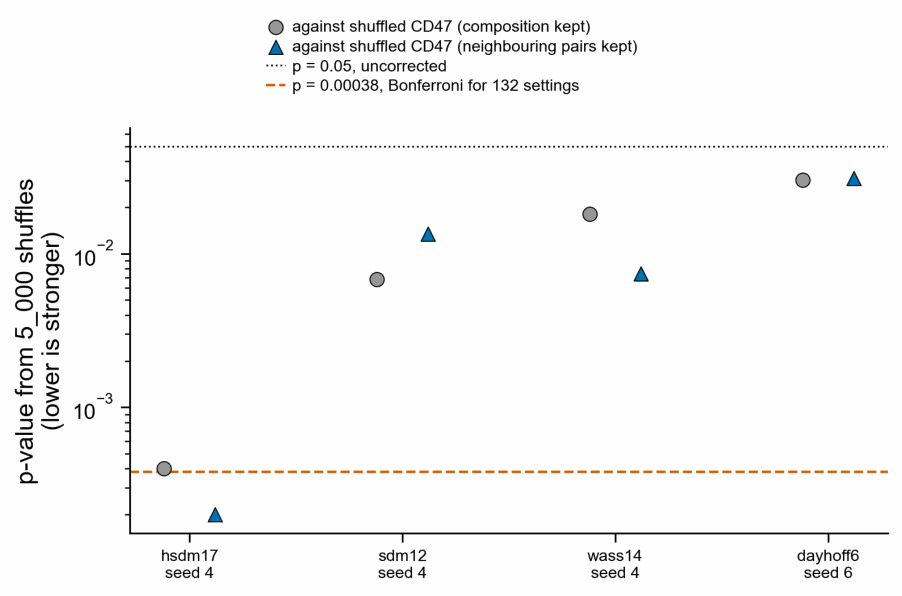

In [13]:
print("The four that beat the uncorrected threshold, re-tested with 5_000 shuffles")
print("of each kind. The Bonferroni threshold for 132 settings is p < 0.00038.")
print(
    follow.select(
        "alphabet",
        "n_classes",
        "seed_length",
        "penalty",
        "score",
        "segment_length",
        "p_composition_null",
        "p_neighbour_pairs_null",
        "survives_bonferroni_both_nulls",
    )
)
print(
    f"\nSurviving both nulls at the corrected threshold: "
    f"{follow.filter(pl.col('survives_bonferroni_both_nulls')).height} of {follow.height}"
)
show("276k_seed_extend_null_tests", aspect=0.65)

**Figure 276k.** Each candidate's p-value against both nulls, with the corrected threshold.
`figures/276k_seed_extend_null_tests.png`. The `hsdm17` hit lands on p = 0.0004 against the
composition null and 0.0002 against the stricter one, with the corrected threshold at
0.00038, so it misses on one null and clears it on the other. The other three are an order
of magnitude away. Nothing survives both.

Where each candidate's score actually comes from:
shape: (4, 9)
┌──────────┬─────────────┬─────────────┬────────────────┬───┬────────────┬───────────────────────┬────────────────────────┬─────────────────────┐
│ alphabet ┆ seed_length ┆ total_score ┆ segment_length ┆ … ┆ loop_score ┆ loop_score_per_column ┆ other_score_per_column ┆ loop_share_of_score │
│ ---      ┆ ---         ┆ ---         ┆ ---            ┆   ┆ ---        ┆ ---                   ┆ ---                    ┆ ---                 │
│ str      ┆ i64         ┆ f64         ┆ i64            ┆   ┆ f64        ┆ f64                   ┆ f64                    ┆ f64                 │
╞══════════╪═════════════╪═════════════╪════════════════╪═══╪════════════╪═══════════════════════╪════════════════════════╪═════════════════════╡
│ hsdm17   ┆ 4           ┆ 6.0         ┆ 36             ┆ … ┆ 1.0        ┆ 0.143                 ┆ 0.172                  ┆ 0.167               │
│ sdm12    ┆ 4           ┆ 6.5         ┆ 38             ┆ … 

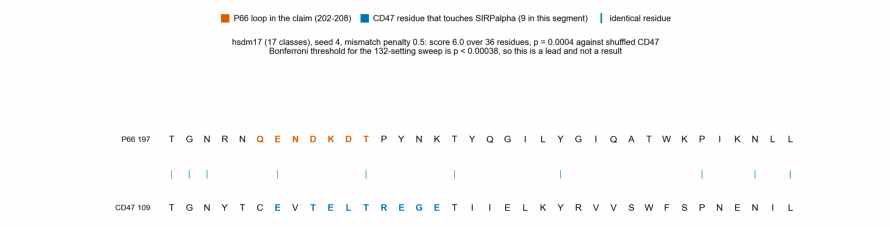

In [14]:
print("Where each candidate's score actually comes from:")
print(
    contrib.select(
        "alphabet",
        "seed_length",
        "total_score",
        "segment_length",
        "loop_columns",
        "loop_score",
        "loop_score_per_column",
        "other_score_per_column",
        "loop_share_of_score",
    )
)
print("\nWhat sits opposite the loop in each segment:")
print(
    contrib.select(
        "alphabet",
        "p66_loop_residues",
        "cd47_residues_opposite_loop",
        "n_face_residues_opposite_loop",
    )
)
worse = contrib.filter(
    pl.col("loop_score_per_column") < pl.col("other_score_per_column")
)
print(
    f"\nCandidates where the loop scores worse per column than the rest of its own "
    f"segment: {worse.height} of {contrib.height}"
)
show("276j_seed_extend_best_alignment", aspect=0.24)

**Figure 276j.** The strongest candidate written out residue by residue.
`figures/276j_seed_extend_best_alignment.png`. Vermillion is the P66 loop, blue is a CD47
residue that touches SIRPalpha, a green bar is an identical residue.

**What it says, and it is the closest thing in this notebook to support for the claim.**
`hsdm17` with a 4-class seed finds a 36-residue ungapped segment, P66 197-232 against CD47
109-144, which is 92% inside CD47's ectodomain and covers 9 of the 21 face residues
(115 and 117-124, the face's longest run). It covers the whole loop including both
aspartates, and opposite `QENDKDT` sits `CEVTELT`, 5 residues of which touch SIRPalpha.
`sdm12` independently finds the same segment. Both are acidic stretches, which is what the
claim is about.

**Why it still is not support.** Four reasons, in order of how much they matter:

1. **The loop is the worst part of the segment.** Splitting the score column by column: the
   loop contributes 1.0 of `hsdm17`'s 6.0, at 0.143 per column against 0.172 for the rest
   of the same segment. In `dayhoff6` the loop contributes **-2.0**, so that segment scores
   well in spite of the loop. In 3 of the 4 candidates the loop scores worse per column than
   its own flanks. The alignment is carried by `TGN` against `TGN` at the start and
   `NIL` against `NLL` at the end, both outside the loop.
2. **Nothing survives its own multiplicity.** 4 of 132 settings beat p < 0.05, against 6.6
   expected by chance; and at the corrected threshold none clears both nulls.
3. **Only the most lenient penalty produces any of it.** All four candidates are at penalty
   0.5, the setting that elsewhere in the same sweep extends through entire proteins.
4. **The one candidate where the loop is the whole segment misses the face.** `wass14` puts
   `QENDKDT` against `NENILIV` with a score the loop fully earns, but that stretch of CD47
   touches no face residue at all.

**What would settle it.** The `hsdm17` segment is a real lead and is worth one dedicated
test rather than a sweep: fix the alphabet, seed length and penalty in advance, and ask
whether a segment like it appears for the claimed pair more often than for P66 against a
set of human proteins matched on length and acidic content. That is a different experiment
from this notebook, and it is the one that would turn p = 0.0004 at setting 1 of 132 into a
number worth quoting.

## 7. Citations

Every paper here was looked up with the PubMed tool in this session and the metadata it
returned is pasted below; no DOI, PMID or URL is written from memory. According to PubMed:

| what it is cited for | paper | PMID | DOI |
|---|---|---|---|
| the mimicry claim under test | Tal MC, Hansen PS, Ogasawara HA, *et al.* "P66 is a bacterial mimic of CD47 that binds the anti-phagocytic receptor SIRPα and facilitates macrophage evasion by." *bioRxiv*, 30 April 2024 | 38746193 | [10.1101/2024.04.29.591704](https://doi.org/10.1101/2024.04.29.591704) |
| PDB 2JJS, the CD47 / SIRPα complex the face is measured from | Hatherley D, Graham SC, Turner J, Harlos K, Stuart DI, Barclay AN. "Paired receptor specificity explained by structures of signal regulatory proteins alone and complexed with CD47." *Mol Cell* 31(2):266-77, 25 July 2008 | 18657508 | [10.1016/j.molcel.2008.05.026](https://doi.org/10.1016/j.molcel.2008.05.026) |
| P66 as an integrin ligand, the measured part of the loop's function | Coburn J, Cugini C. "Targeted mutation of the outer membrane protein P66 disrupts attachment of the Lyme disease agent, *Borrelia burgdorferi*, to integrin alphavbeta3." *Proc Natl Acad Sci USA* 100(12):7301-6, 14 May 2003 | 12748384 | [10.1073/pnas.1131117100](https://doi.org/10.1073/pnas.1131117100) |
| US-align, comparisons 1 and the superposition | Zhang C, Shine M, Pyle AM, Zhang Y. "US-align: universal structure alignments of proteins, nucleic acids, and macromolecular complexes." *Nat Methods* 19(9):1109-1115, 29 August 2022 | 36038728 | [10.1038/s41592-022-01585-1](https://doi.org/10.1038/s41592-022-01585-1) |
| Foldseek, comparison 2 | van Kempen M, Kim SS, Tumescheit C, Mirdita M, Lee J, Gilchrist CLM, Söding J, Steinegger M. "Fast and accurate protein structure search with Foldseek." *Nat Biotechnol* 42(2):243-246, 8 May 2023 | 37156916 | [10.1038/s41587-023-01773-0](https://doi.org/10.1038/s41587-023-01773-0) |
| the AlphaFold models and what pLDDT means | Varadi M, Anyango S, Deshpande M, *et al.* "AlphaFold Protein Structure Database: massively expanding the structural coverage of protein-sequence space with high-accuracy models." *Nucleic Acids Res* 50(D1):D439-D444, 7 January 2022 | 34791371 | [10.1093/nar/gkab1061](https://doi.org/10.1093/nar/gkab1061) |

Two things in this notebook have no citation that could be fetched:

* **The P-SEA CA-geometry criteria used to call coil in section 5.** I cannot verify a
  citation for this claim: PubMed returned nothing for the P-SEA paper under several
  queries. The criteria are stated in the code so a reader can check them directly, and
  they affect only which 10 background loops were drawn, not any measurement.
* **The claim that the loop is "a predicted extracellular loop".** The quoted preprint
  asserts it; no separate citation was fetched for the topology prediction itself.

## 8. Summary and conclusions

**Does the structure support mimicry? No, on all three comparisons, and the claimed pair
loses to both backgrounds.**

| comparison | the claimed pair | the background | beats it? |
|---|---|---|---|
| whole fold, TM-score against CD47's IgV domain | 0.342, 68 residues aligned, 4.34 Å RMSD | 20 immunoglobulin domains, 0.507 to 0.704, median 0.614 | no, below all 20 |
| Foldseek against the PDB | best E = 0.128, no CD47 entry in 176 hits, although 2JJS is in the database | nothing below E = 0.001 at all; top hits are bacterial outer-membrane β-barrels | no hit to beat |
| the loop on the binding face, backbone RMSD | 1.91 Å, best window CD47 29-35 | 10 other P66 loops, 0.94 to 1.82 Å, median 1.07 Å | no, worst of 11 |

Claim sentences:

* **P66's AlphaFold model does not share CD47's immunoglobulin fold**: TM-score 0.342
  normalised by CD47, below the 0.5 same-fold line and below all 20 unrelated
  immunoglobulin domains, whose lowest score is 0.507.
* **Foldseek finds P66 to be a bacterial outer-membrane β-barrel and finds no CD47**: the
  176 PDB hits are led by FapF and PagP at E = 0.128, no hit reaches E = 0.001, and no CD47
  or SIRPα entry appears even though 2JJS is in the searched database.
* **The loop in the claim fits CD47's SIRPα-binding face worse than ordinary P66 loops
  do**: 1.91 Å backbone RMSD against a median of 1.07 Å for 10 other 7-residue P66 loops,
  and in the whole-fold superposition its centre lands 55 Å from the centre of the face,
  off a domain only 45 Å across at its widest.
* **kmerseek's silence here is forced, and carries no weight either way**: none of the 326
  shared k-mers touches the loop across the 16 alphabets and 27 settings PR 96 searched,
  and at every one of those settings no k-mer covering the loop occurs in CD47 at all. 8 of
  19 alphabets write the loop's seven polar residues as one repeated class; in the other 11
  the string varies but its k-mers are absent from CD47 anyway. The zero says where the
  sweep looked, not whether the mimicry is real.

### The strongest argument against this result

**The P66 model is too poor to settle anything, and that cuts against the negative as hard
as it cuts against the claim.** Mean pLDDT 29.0, with 99.8% of residues below AlphaFold's
"very low" line of 50, and no experimental structure to fall back on. TM-score, Foldseek's
3Di alphabet and a backbone RMSD all read the coordinates as if they meant something, and
here they may not. A TM-score of 0.342 against CD47 is what a wrong model would give as
readily as what a genuinely different fold would give.

Three things limit how far that objection goes, and none of them removes it:

1. Foldseek still recovers the right biology from the same model: its best hits are
   outer-membrane β-barrels, which is what P66 is known to be. A model carrying no usable
   signal would not do that.
2. Comparison 3 is internally fair. The claimed loop and the 10 background loops come from
   the same bad model, so whatever the model gets wrong, it gets wrong for all of them.
3. The paper's own figure cites an AlphaFold2 model of P66 for the same loop. If the model
   is too poor to test the claim, it is also too poor to have supported it.

The way to settle this is a better structure, not a better analysis: an experimental P66
structure, or a model built with a deeper alignment than the AlphaFold database entry
carries, and then a direct test of P66 against SIRPα rather than against CD47. The
mimicry claim's own measured evidence is binding and genetics, which this notebook does not
touch and does not contradict. What it does say is that nothing in the shape of the only
public P66 structure supports mimicry, and that the shortest stretch of it the claim rests
on fits CD47's binding face worse than the protein's other loops do.